# Session 0 — Teaching a Machine from Examples

Suppose you want a program that names a flower from its measurements. You could write rules by hand: short petals mean *setosa*, then check the width, then add an exception for the awkward cases. The list gets long quickly. Machine learning takes a different route: you show the computer flowers whose species is already known, and it works out the rules itself.

This notebook follows one complete experiment from start to finish. The code is short. The order of the steps is what you will reuse in every later session.

**New to notebooks, to Python or to AI?** Read *Before You Start* (`prelim_before_you_start.ipynb`) first. It shows how to run a notebook, how to follow the code without knowing Python, and the words this session uses. You don't need to read the code to follow this session: the text before each code cell says what it does, and the text after it reads the output.

**By the end of the session you should be able to:**

1. explain why part of the data is kept hidden until the end;
2. say what a baseline is and why a model's score means little without one;
3. look at a model's individual mistakes instead of only its accuracy.

**To run it yourself** open the notebook in Google Colab or JupyterLab and run the cells from the top; it takes a few seconds and needs `numpy`, `pandas`, `matplotlib` and `scikit-learn`, which Colab already has. Every output is already saved, so you can also just read it. If you run it, your numbers may differ slightly from the ones quoted in the text.

## 1. The data

We use the Iris dataset: 150 flowers, each with four measurements (in centimetres) and a known species. Each row is one flower. The four columns are the **features** (the inputs). The species is the **target** (the answer we want to predict).

Predicting a category like species is **classification**. Predicting a number, such as a price, is **regression**. This session is classification.

The cell below loads the toolboxes the session uses and the 150 flowers, then shows the first five rows. The species are stored as numbers, 0 for setosa, 1 for versicolor and 2 for virginica, because models work with numbers.

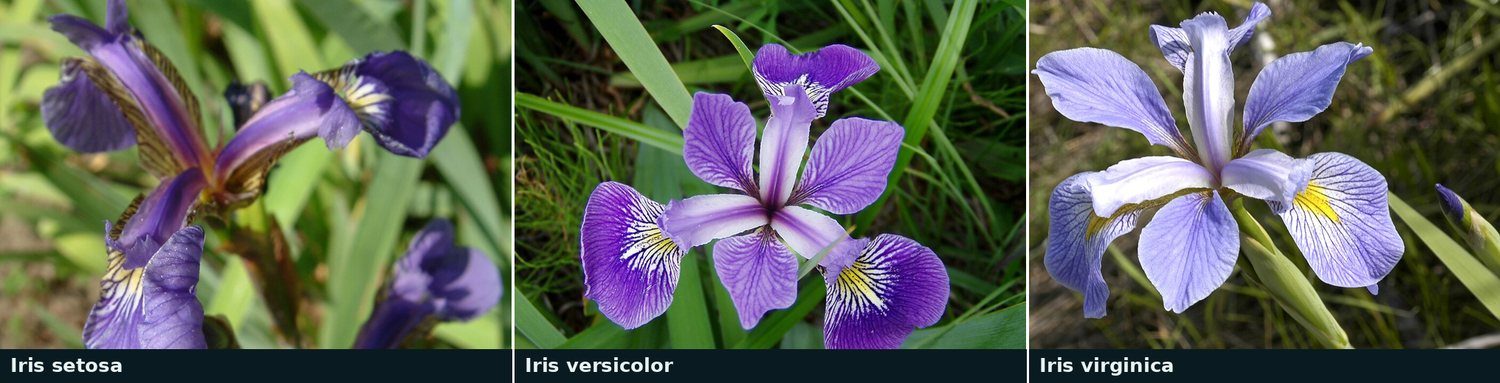

*Figure 0.1 — The three species in the dataset. In an iris the three drooping outer parts are the sepals and the three smaller upright inner parts are the petals; the four measurements in the table are the length and width of each. Photos from Wikimedia Commons: Radomil (CC BY-SA 3.0), Danielle Langlois (CC BY-SA 3.0) and Frank Mayfield (CC BY-SA 2.0), cropped and resized.*

In [1]:
# Load the toolboxes: numpy and pandas handle tables of numbers, matplotlib draws plots,
# and scikit-learn (sklearn) provides the dataset, the model and the ways of scoring it.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report

SEED = 42                               # a fixed starting point for everything random, so each run gives the same result
iris = load_iris(as_frame=True)         # the 150 flowers
X, y = iris.data, iris.target           # X: the four measurements of each flower; y: its species, as 0, 1 or 2
species = iris.target_names.tolist()    # the names of species 0, 1 and 2

print("Species:", species)
print("Shape:", X.shape)
X.head()

Species: ['setosa', 'versicolor', 'virginica']
Shape: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## 2. Hiding part of the data

If you check a model on the same flowers it learned from, a high score doesn't tell you whether it found a pattern or just remembered those rows, in the way a student who has seen the exam in advance can score full marks without understanding anything. So we split the data first:

- the **training set** (112 flowers) is what the model learns from;
- the **test set** (38 flowers) is kept back and used once, at the end, to measure the finished model.

The split is random, but the seed fixes it, so it comes out the same every time. The setting `stratify=y` shares each species out between the two sets in the same proportion.

In [2]:
# Split the flowers at random: a quarter of them (test_size=0.25) are kept back for the test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print(len(X_train), "training flowers,", len(X_test), "test flowers")

112 training flowers, 38 test flowers


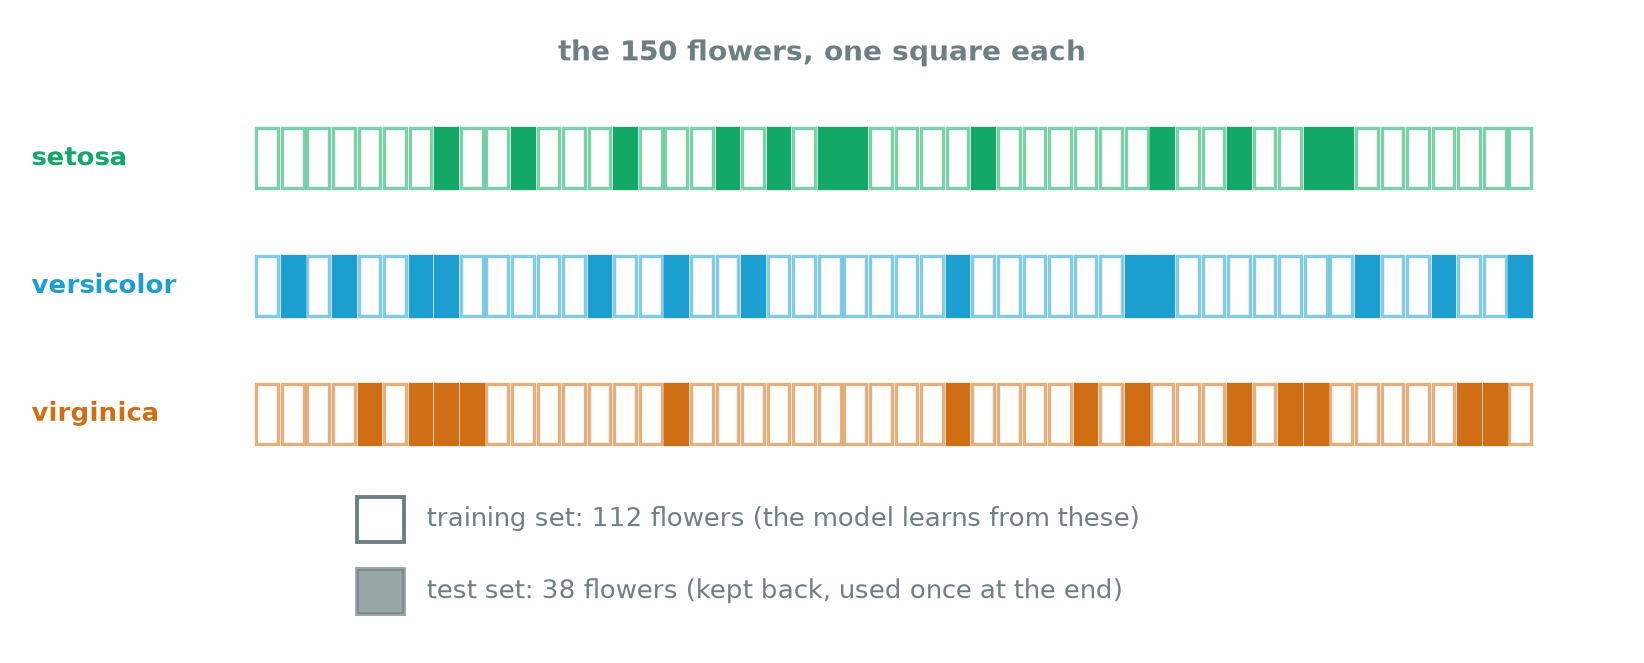

*Figure 0.2 — The 150 flowers split into 112 for training and 38 for testing. Filled squares are the test flowers. Because of `stratify=y`, each species appears in both sets in the same proportion: 12, 13 and 13 of each species are in the test set.*

## 3. The baseline: what does doing nothing clever score?

Before building a model, set a reference score. Our baseline always answers with the most common species in the training set. We score it by its **accuracy**: the share of the test flowers it gets right.

> **Pause:** what accuracy would you be happy with for this problem? Decide before scrolling.

In [3]:
majority_class = y_train.mode().iloc[0]      # the most common species among the training flowers
# Score the answer "always that species" on the test flowers
baseline_accuracy = accuracy_score(y_test, np.full(len(y_test), majority_class))
print(f"Baseline: always predict '{species[majority_class]}' -> accuracy {baseline_accuracy:.3f}")

Baseline: always predict 'setosa' -> accuracy 0.316


The baseline scores 0.316 on the test set: about one flower in three, which is what you would expect with three species of similar size.

Any real model has to beat 0.316 by a clear margin before it deserves any credit. Here that is easy, but you will meet datasets in Session 4 where the baseline is already above 99%.

## 4. A rule written by hand

The baseline is the lowest bar. A fairer one is the program you would have written without machine learning, so here is the rule from the opening paragraph. The table shows the smallest and largest petal of each species in the training set:

In [4]:
# First look at the training flowers: the shortest and longest, narrowest and widest petal of each species
names = y_train.map(dict(enumerate(species)))                     # species names instead of 0, 1, 2
print(X_train.groupby(names)[["petal length (cm)", "petal width (cm)"]].agg(["min", "max"]))


# The rule from the opening paragraph, with two thresholds read off that table
def hand_rule(X):
    short_petal = X["petal length (cm)"] < 2.5
    narrow_petal = X["petal width (cm)"] < 1.75
    return np.where(short_petal, 0, np.where(narrow_petal, 1, 2))   # short: setosa (0); else narrow: versicolor (1); else virginica (2)


print(f"\nHand-written rule: training accuracy {accuracy_score(y_train, hand_rule(X_train)):.3f}, test accuracy {accuracy_score(y_test, hand_rule(X_test)):.3f}")
print("Test flowers the rule gets wrong:", X_test.index[hand_rule(X_test) != y_test.to_numpy()].tolist())

           petal length (cm)      petal width (cm)     
                         min  max              min  max
target                                                 
setosa                   1.1  1.9              0.1  0.6
versicolor               3.0  5.1              1.0  1.8
virginica                4.8  6.9              1.5  2.5

Hand-written rule: training accuracy 0.964, test accuracy 0.947
Test flowers the rule gets wrong: [134, 106]


- **Petal length** separates setosa cleanly: the longest setosa petal is 1.9 cm and the shortest of the others is 3.0 cm, so 2.5 cm splits them.
- **Petal width** separates the other two only roughly. Versicolor runs from 1.0 to 1.8 cm and virginica from 1.5 to 2.5 cm, so any threshold puts some flowers on the wrong side. The rule uses 1.75 cm.

In words: if the petal is shorter than 2.5 cm, say setosa; otherwise, if it is narrower than 1.75 cm, say versicolor; otherwise, say virginica.

The rule scores 0.964 on the training flowers and 0.947 on the test flowers: it gets 36 of the 38 right.

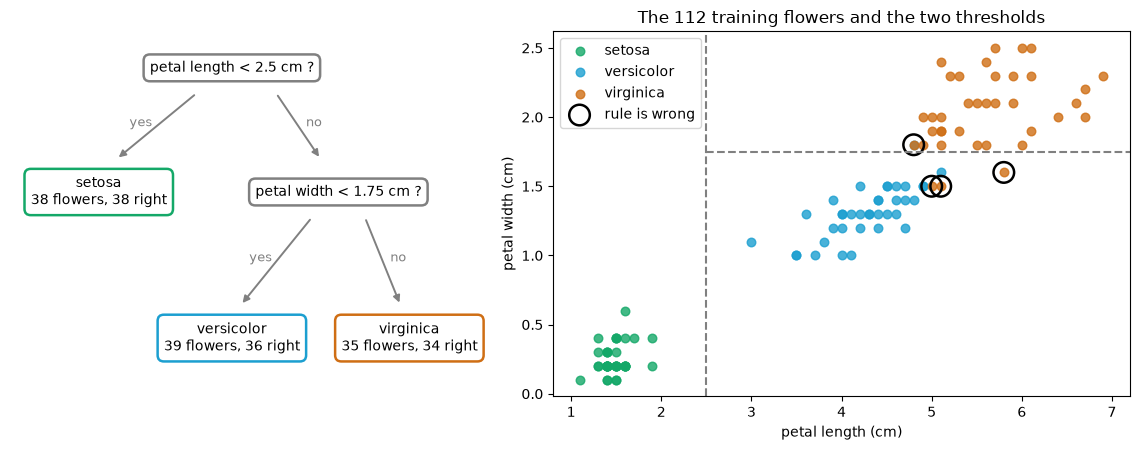

In [5]:
# @title Draw the hand-written rule (code that only draws the figure; you can skip it)
colors = ["#14A868", "#1C9FD0", "#CF6E14"]
rule = hand_rule(X_train)
fig, (tree, ax) = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1, 1.3]})

tree.set(xlim=(0, 10), ylim=(0, 10)); tree.axis("off")
def node(x, y, text, color="gray"):
    tree.text(x, y, text, ha="center", va="center", fontsize=10, bbox=dict(boxstyle="round,pad=0.45", fc="none", ec=color, lw=1.8))
node(5, 9, "petal length < 2.5 cm ?")
node(7.4, 5.6, "petal width < 1.75 cm ?")
for k, (x, y) in enumerate([(2, 5.6), (5, 1.6), (9, 1.6)]):
    reached = rule == k
    node(x, y, f"{species[k]}\n{reached.sum()} flowers, {(y_train.to_numpy()[reached] == k).sum()} right", colors[k])
for (x0, y0, x1, y1, label) in [(4.2, 8.3, 2.4, 6.5, "yes"), (6.0, 8.3, 7.0, 6.5, "no"), (6.8, 4.9, 5.2, 2.5, "yes"), (8.0, 4.9, 8.8, 2.5, "no")]:
    tree.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color="gray", lw=1.4))
    tree.text((x0 + x1) / 2 + (-0.35 if x1 < x0 else 0.35), (y0 + y1) / 2, label, fontsize=9, color="gray", ha="center")

for k, name in enumerate(species):
    rows = X_train[y_train == k]
    ax.scatter(rows["petal length (cm)"], rows["petal width (cm)"], s=38, alpha=0.8, color=colors[k], label=name)
wrong_rows = X_train[rule != y_train.to_numpy()]
ax.scatter(wrong_rows["petal length (cm)"], wrong_rows["petal width (cm)"], s=220, facecolors="none", edgecolors="k", linewidths=1.8, label="rule is wrong")
ax.axvline(2.5, color="gray", ls="--"); ax.hlines(1.75, 2.5, 7.2, color="gray", ls="--")
ax.set(xlabel="petal length (cm)", ylabel="petal width (cm)", xlim=(0.8, 7.2), title=f"The {len(X_train)} training flowers and the two thresholds")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

*Figure 0.3 — The hand-written rule. Left: the two questions, with how many of the 112 training flowers reach each answer. Right: the same two thresholds drawn on the training flowers' petals; circled flowers are the ones the rule gets wrong.*

## 5. A first model

Now a model that finds its own rule. We use **logistic regression**. Despite its name, it picks a category; it doesn't predict a number. It works like a score card: for each species, it multiplies each measurement by a **weight** and adds the results up into a score, then picks the species with the highest score. **Training** sets the weights so that as many training flowers as possible get the right species. Before that, a scaling step (`StandardScaler`) puts the four measurements on a similar scale, so no measurement counts for more just because its numbers are bigger.

In the code, `fit` is where learning happens: the model sets its weights using the training flowers only. `predict` applies those weights to new flowers and changes nothing.

> **Pause:** the model makes three mistakes on the test set. Which species do you expect it to mix up? The petal ranges in section 4 are a clue.
>
> - **A.** Setosa and versicolor.
> - **B.** Setosa and virginica.
> - **C.** Versicolor and virginica.
> - **D.** A mix: one mistake in each pair of species.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**C.** All three mistakes are between versicolor and virginica: two virginica flowers are called versicolor and one versicolor is called virginica. All 12 setosa flowers are right, which the petal ranges in section 4 predict.

</details>

In [6]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))   # the scaling step, then the model
model.fit(X_train, y_train)                  # training: set the weights from the training flowers
train_accuracy = model.score(X_train, y_train)
predictions = model.predict(X_test)          # the model's answers for the 38 test flowers
print(f"Training accuracy: {train_accuracy:.3f}")
print(f"Test accuracy:     {accuracy_score(y_test, predictions):.3f}")

Training accuracy: 0.964
Test accuracy:     0.921


The test accuracy is 0.921, against 0.316 for the baseline and 0.947 for the hand-written rule. The rule wins by one flower out of 38, which is too small a difference to call either of them better. On a problem this small, a person who looks at the data can match the model.

The difference is in how the rule was made. You read two thresholds off a table; the model found its weights from the numbers alone, with the same `fit` call that works when nobody can read rules off a table, such as the 784 pixels of each digit in Session 8. Either way, the comparison is the point: a model is worth keeping only if it beats the simplest thing that works.

The training accuracy is 0.964, slightly higher than the test accuracy. A small gap like this is normal, because the model has seen the training flowers and not the test ones. It would be a warning sign if the gap were large; Session 3 shows one.

## 6. Which flowers does it get wrong?

One accuracy number hides where the mistakes are. The **confusion matrix** is a table of counts: each row is a true species, each column is the species the model said. Correct answers sit on the diagonal from top left to bottom right; every other square counts a kind of mistake.

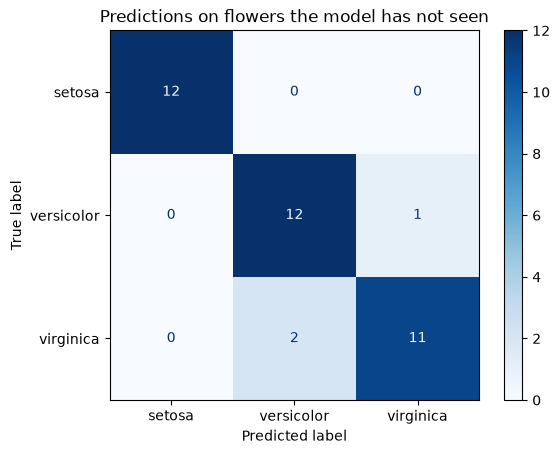

In [7]:
# Count, for each true species, which species the model said, and draw the counts as a table
ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=species, cmap="Blues")
plt.title("Predictions on flowers the model has not seen")
plt.show()

All 12 setosa flowers are right. Every mistake is between *versicolor* and *virginica*: 2 of the 13 virginica flowers are called versicolor, and 1 of the 13 versicolor flowers is called virginica. That is 35 of 38 correct.

In [8]:
wrong = predictions != y_test.to_numpy()           # True for each test flower the model got wrong
errors = X_test.loc[wrong, ["petal length (cm)", "petal width (cm)", "sepal length (cm)", "sepal width (cm)"]].copy()   # their measurements
# Add their real species and the model's answer
errors["actual"] = [species[i] for i in y_test[wrong]]
errors["predicted"] = [species[i] for i in predictions[wrong]]
errors

,petal length (cm),petal width (cm),sepal length (cm),sepal width (cm),actual,predicted
134,5.6,1.4,6.1,2.6,virginica,versicolor
106,4.5,1.7,4.9,2.5,virginica,versicolor
77,5.0,1.7,6.7,3.0,versicolor,virginica


The three wrong flowers, with their measurements:

- Flower 134 is a virginica with a long petal (5.6 cm) but a narrow one (1.4 cm).
- Flower 106 is a virginica with a short petal (4.5 cm), and its sepal is the smallest of the three at 4.9 cm.
- Flower 77 is a versicolor with a petal that is long (5.0 cm) and wide (1.7 cm) for its species.

Each one looks like a member of the other species on the measurements the model relies on most. Flowers 134 and 106 are also the hand-written rule's two mistakes. The plot below shows where they sit.

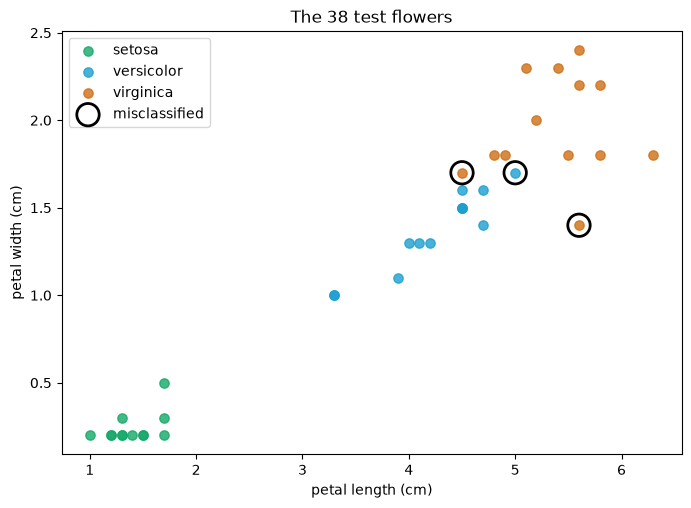

In [9]:
# @title Draw the 38 test flowers and circle the three mistakes (code that only draws the figure; you can skip it)
fig, ax = plt.subplots(figsize=(8, 5.5))
colors = ["#14A868", "#1C9FD0", "#CF6E14"]          # setosa, versicolor, virginica: the colours of the other figures
for k, name in enumerate(species):
    rows = X_test[y_test == k]
    ax.scatter(rows["petal length (cm)"], rows["petal width (cm)"], label=name, s=45, alpha=0.8, color=colors[k])
bad = X_test[wrong]
ax.scatter(bad["petal length (cm)"], bad["petal width (cm)"], s=260, facecolors="none", edgecolors="k", linewidths=2, label="misclassified")
ax.set(xlabel="petal length (cm)", ylabel="petal width (cm)", title="The 38 test flowers")
ax.legend()
plt.show()

Setosa (green) sits far from the other two, which is why the model never confuses it. Versicolor (blue) and virginica (orange) overlap in the middle, and all three circled mistakes fall in that overlap: flower 106 is an orange point inside the blue cluster, flower 77 is a blue point at the edge of the orange one, and flower 134 sits below the orange group because its petal is narrow.

No model using these four measurements can fully separate flowers that overlap like this. To do better, you would collect another measurement or more flowers, rather than tune the model. This is **error analysis**: look at the failures, then ask whether the data or the model is the limit.

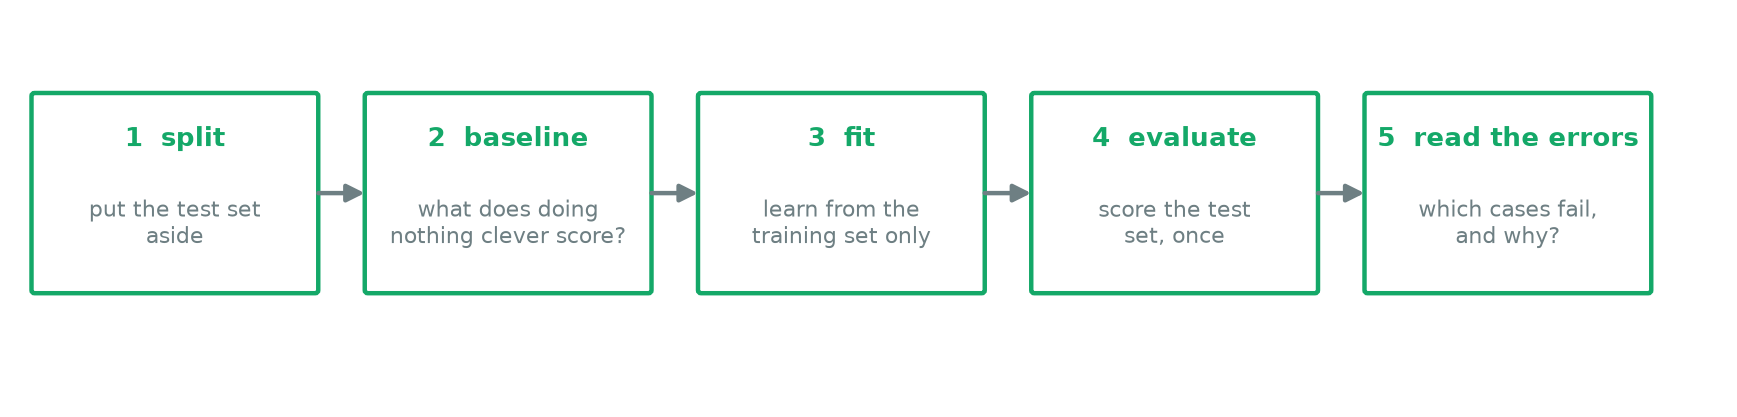

*Figure 0.4 — The five-step experiment chain that every later session follows: split, baseline, fit, evaluate, read the errors. A small version of this strip opens each session with that session's step highlighted.*

## The pattern to take away

Every experiment in this course follows the same chain:

1. **split** the data and put the test set aside;
2. set a **baseline**;
3. **fit** a model on the training set;
4. **evaluate** on the test set;
5. **read the errors**.

Between steps 2 and 3, compare with the rule you would have written by hand: that is the bar a model has to clear to be worth keeping.

Each later session adds something to one of these steps. Session 2 shows what happens when the split is done wrongly, and Session 4 reworks step 4.

## Where the ideas in this course came from

Most of the methods in this course are older than they look. The dates below are the papers or events the course's sessions build on.

| Year | What happened | Session |
|---|---|---|
| 1936 | Ronald Fisher publishes the iris measurements used in this session, collected by the botanist Edgar Anderson. | 0 |
| 1958 | Frank Rosenblatt describes the perceptron, a single unit that learns its weights from examples. | 6 |
| 1969 | Marvin Minsky and Seymour Papert's book *Perceptrons* shows that a single unit cannot learn some simple patterns, such as XOR. | 6 |
| 1986 | David Rumelhart, Geoffrey Hinton and Ronald Williams popularise backpropagation, which trains networks with hidden layers. | 6, 7 |
| 1997 | Sepp Hochreiter and Jürgen Schmidhuber introduce the LSTM, a network that reads sequences. | 10 |
| 1998 | Yann LeCun and colleagues publish LeNet-5, a convolutional network for handwritten digits, with the MNIST digits used in Session 8. | 8 |
| 2012 | AlexNet, a deep convolutional network, wins the ImageNet image-classification contest with a top-5 error of 15.3%, against 26.2% for the next entry. | 8, 9 |
| 2017 | "Attention Is All You Need" introduces the transformer. | 11 |
| 2018 | BERT, a transformer pretrained on large amounts of text, is published. | 11 |
| 2022 | ChatGPT puts a large language model in front of the public. | 12 |

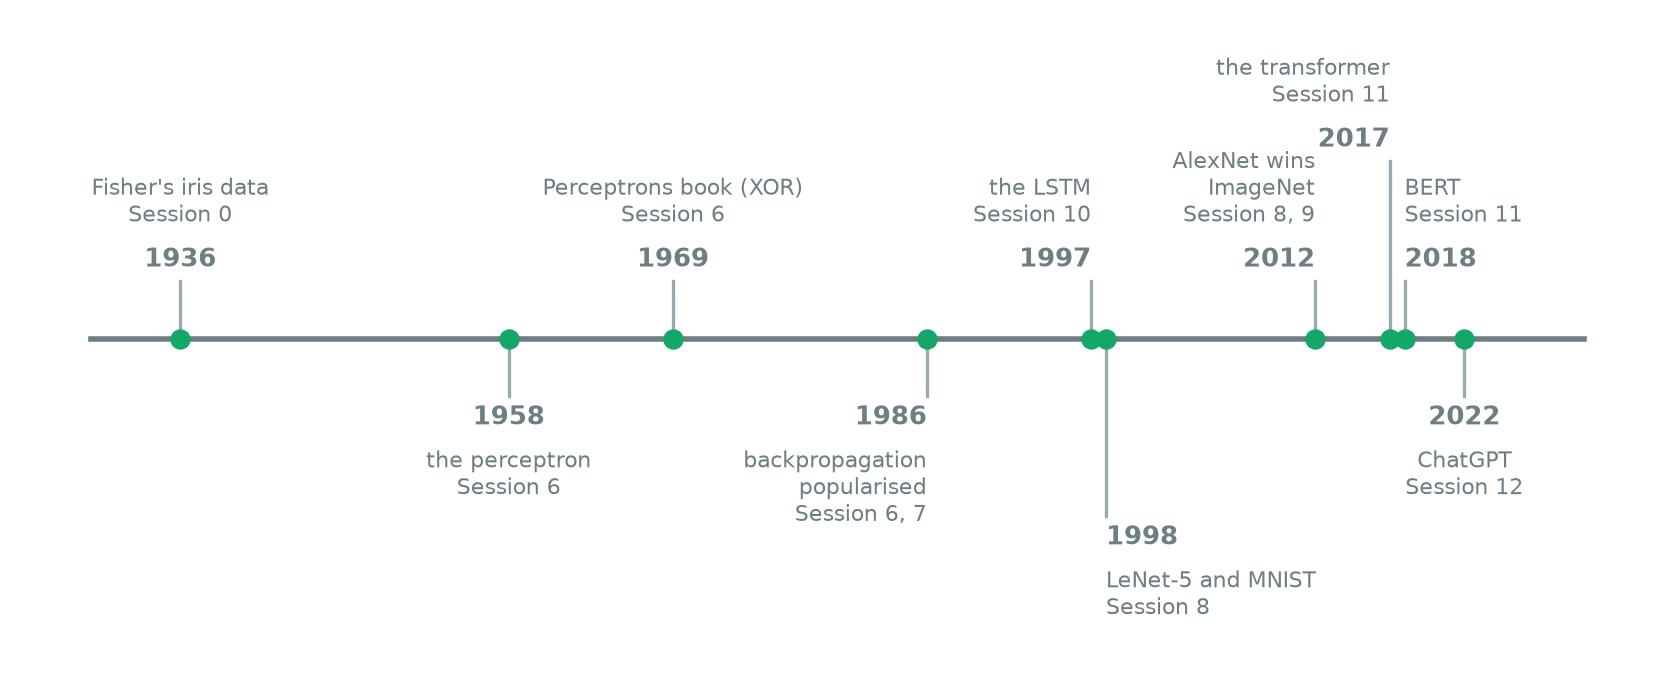

*Figure 0.5 — The history table as a timeline. Most of the methods in the course are older than they look; the labels near the line give the session that builds on each.*

---

# Going deeper

*The rest of this notebook is for reading after the session.*

## The notation behind the experiment

A supervised dataset is a list of pairs $(x_i, y_i)$: an input and its correct answer. For Iris, $x_i$ holds four measurements and $y_i$ is the species. Stacking the inputs gives a table $X$ with $n$ rows (examples) and $d$ columns (features). Here $n=150$ and $d=4$.

A model is a function $\hat y = f_\theta(x)$ whose **parameters** $\theta$ are set during training. The hat on $\hat y$ marks a prediction, to separate it from the true answer $y$. For logistic regression, $\theta$ is a weight for each feature and each species; for the neural networks in Session 6 onwards it is thousands or millions of weights.

## Standardisation

The scaler replaces each value $x$ with $(x-\mu)/\sigma$, where $\mu$ and $\sigma$ are that column's mean and standard deviation **in the training set**. The test set is rescaled with the training values, so no information from the test set reaches the model. Session 2 explains why this matters.

## What logistic regression computes

For each species $k$ the model forms a score $z_k = w_k^\top x + b_k$, then turns the scores into probabilities that add up to 1 with the softmax function:

$$
P(\text{species}=k \mid x)=\frac{e^{z_k}}{\sum_j e^{z_j}} .
$$

`predict` returns the species with the highest probability.

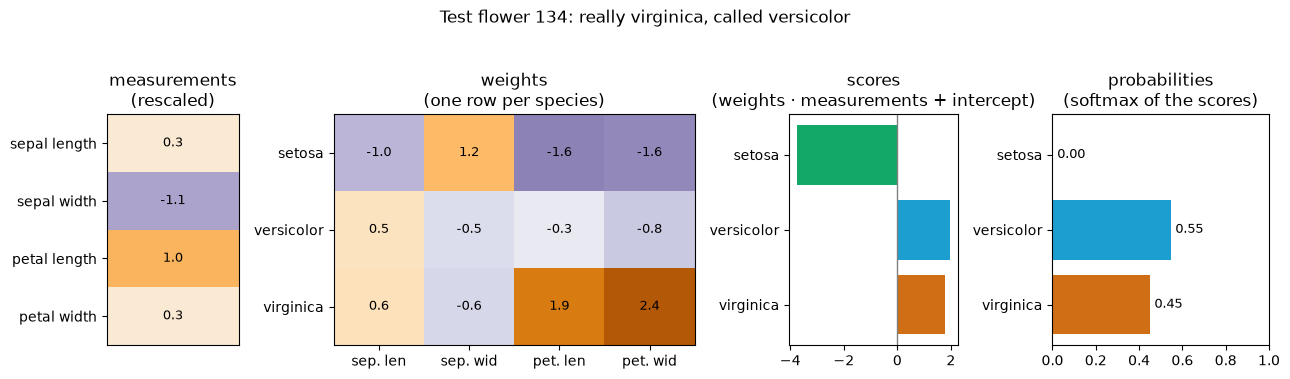

In [10]:
# @title Draw the model's arithmetic for one test flower (code that only draws the figure; you can skip it)
import numpy as np
pos = int(np.flatnonzero(predictions != y_test.to_numpy())[0])
flower = X_test.iloc[[pos]]
x = model[0].transform(flower)[0]                       # the four measurements after StandardScaler
W, b = model[1].coef_, model[1].intercept_              # one row of four weights per species, one intercept per species
scores = W @ x + b
probs = np.exp(scores - scores.max()) / np.exp(scores - scores.max()).sum()
assert np.allclose(probs, model.predict_proba(flower)[0])      # the same numbers the model reports

colors = ["#14A868", "#1C9FD0", "#CF6E14"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), gridspec_kw={"width_ratios": [0.55, 1.5, 0.7, 0.9]})
axes[0].imshow(x[:, None], cmap="PuOr_r", vmin=-2.5, vmax=2.5, aspect="auto")
axes[0].set(xticks=[], yticks=range(4), yticklabels=[c.replace(" (cm)", "") for c in X.columns], title="measurements\n(rescaled)")
im = axes[1].imshow(W, cmap="PuOr_r", vmin=-3, vmax=3, aspect="auto")
axes[1].set(xticks=range(4), xticklabels=["sep. len", "sep. wid", "pet. len", "pet. wid"], yticks=range(3), yticklabels=species, title="weights\n(one row per species)")
for i in range(3):
    for j in range(4): axes[1].text(j, i, f"{W[i, j]:.1f}", ha="center", va="center", fontsize=9)
for k in range(4): axes[0].text(0, k, f"{x[k]:.1f}", ha="center", va="center", fontsize=9)
axes[2].barh(range(3), scores, color=colors); axes[2].invert_yaxis(); axes[2].axvline(0, color="gray", lw=1)
axes[2].set(yticks=range(3), yticklabels=species, title="scores\n(weights · measurements + intercept)")
axes[3].barh(range(3), probs, color=colors); axes[3].invert_yaxis(); axes[3].set(xlim=(0, 1), yticks=range(3), yticklabels=species, title="probabilities\n(softmax of the scores)")
for k in range(3): axes[3].text(probs[k] + 0.02, k, f"{probs[k]:.2f}", va="center", fontsize=9)
fig.suptitle(f"Test flower {flower.index[0]}: really {species[y_test.iloc[pos]]}, called {species[predictions[pos]]}", y=1.04)
plt.tight_layout(); plt.show()

*Figure 0.6 — What the model computes for one test flower (the first one it gets wrong). The four rescaled measurements are multiplied by each species' weights and added to its intercept, giving three scores; softmax turns the scores into probabilities.*

## Accuracy, precision and recall

Accuracy is one number for the whole test set. Precision and recall look at one species at a time:

$$
\text{accuracy}=\frac{\text{correct predictions}}{\text{all predictions}},\quad
\text{precision}=\frac{TP}{TP+FP},\quad
\text{recall}=\frac{TP}{TP+FN},
$$

where $TP$, $FP$ and $FN$ count true positives, false positives and false negatives for one species.

The cell below prints them for each species.

In [11]:
print(classification_report(y_test, predictions, target_names=species))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.86      0.92      0.89        13
   virginica       0.92      0.85      0.88        13

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38



For versicolor, **precision** answers "when the model says versicolor, how often is it right?" (0.86), and **recall** answers "of the real versicolor flowers, how many did it find?" (0.92). The report also gives **F1**, which combines precision and recall into one number, and **support**, the number of test flowers of each species. Session 4 returns to precision and recall.